# NLP Sentiment Classification on Customer Reviews (TF-IDF)
### Task 4: Preprocess Raw Textual Corpus, Extract TF-IDF Embeddings, and Classify Review Polarity

This Jupyter Notebook implements an end-to-end Natural Language Processing (NLP) sentiment analysis system:
1. **Corpus Ingestion**: Load raw customer review records.
2. **Text Cleaning & Normalization**: Strip HTML tags, remove URLs, filter non-alphabetic tokens, remove stopwords, and apply Porter Stemming.
3. **TF-IDF Feature Representation**: Extract unigram and bigram TF-IDF numerical vectors with `max_features=5000`.
4. **Supervised Classifier Training**: Fit **Multinomial Naive Bayes (MultinomialNB)** and **Logistic Regression**.
5. **Benchmarking**: Evaluate Accuracy, Precision, Recall, F1-Score, and ROC-AUC curves.
6. **Feature Interpretability**: Visualize top positive and negative sentiment keywords.
7. **Interactive Sentiment Helper**: Implement `predict_sentiment()` to test live custom phrases with confidence scores.

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

print("✅ All NLP libraries and Scikit-Learn models imported successfully.")

✅ All NLP libraries and Scikit-Learn models imported successfully.


## Step 1: Data Ingestion & NLP Text Cleaning
We load customer reviews and map sentiments (`positive` $\rightarrow 1$, `negative` $\rightarrow 0$). The cleaning pipeline strips HTML tags, punctuation, and stopwords, then reduces tokens to their root morphological stems using the **Porter Stemmer**.

In [2]:
df = pd.read_csv("data/customer_reviews.csv")
# Sample balanced subset of 12,000 reviews
pos = df[df['sentiment'] == 'positive'].sample(6000, random_state=42)
neg = df[df['sentiment'] == 'negative'].sample(6000, random_state=42)
df = pd.concat([pos, neg]).sample(frac=1.0, random_state=42).reset_index(drop=True)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = re.sub(r'<.*?>', ' ', str(text))
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    tokens = text.lower().split()
    filtered = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(filtered)

df['cleaned_review'] = df['review'].apply(clean_text)
print(f"Total reviews processed: {len(df)}")
df[['review', 'cleaned_review', 'sentiment']].head(3)

Total reviews processed: 12000


,review,cleaned_review,sentiment
0,I've watched this documentary twice - and although I'm an major movie buff...,watch documentari twice although major movi buff documentari hold attent film...,positive
1,This is probably the worst movie I've seen in a long time. Independent or not...,probabl worst movi seen long time independ solid write must ditto direct...,negative
2,A fun movie for children and adults alike! Lots of humor and heartwarming...,fun movi children adult alik lot humor heartwarm charm cast charact enjoy...,positive


## Step 2: 80/20 Train/Test Split & TF-IDF Vectorization
We convert the processed vocabulary into a high-dimensional sparse Term Frequency-Inverse Document Frequency matrix with `max_features=5000` and unigram/bigram ranges (`ngram_range=(1, 2)`).

In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['cleaned_review'], df['label'].values,
    test_size=0.20, random_state=42, stratify=df['label'].values
)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

print(f"Training reviews: {X_train_tfidf.shape[0]} | Testing reviews: {X_test_tfidf.shape[0]}")
print(f"TF-IDF Vocabulary Size: {X_train_tfidf.shape[1]} n-gram features")

Training reviews: 9600 | Testing reviews: 2400
TF-IDF Vocabulary Size: 5000 n-gram features


## Step 3: Model Training & Evaluation (MultinomialNB & Logistic Regression)
We fit:
1. **Multinomial Naive Bayes (`MultinomialNB`)**: Probabilistic model applying Bayes theorem with conditional independence assumptions.
2. **Logistic Regression**: Linear classifier minimizing cross-entropy with L2 regularization.

In [4]:
nb_clf = MultinomialNB(alpha=1.0)
lr_clf = LogisticRegression(max_iter=500, random_state=42)

nb_clf.fit(X_train_tfidf, y_train)
lr_clf.fit(X_train_tfidf, y_train)

y_prob_nb = nb_clf.predict_proba(X_test_tfidf)[:, 1]
y_pred_nb = nb_clf.predict(X_test_tfidf)

y_prob_lr = lr_clf.predict_proba(X_test_tfidf)[:, 1]
y_pred_lr = lr_clf.predict(X_test_tfidf)

print("=" * 65)
print("MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_nb, target_names=['Negative', 'Positive'], digits=4))

print("=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_lr, target_names=['Negative', 'Positive'], digits=4))

MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative     0.8565    0.8408    0.8486      1200
    Positive     0.8437    0.8592    0.8514      1200

    accuracy                         0.8500      2400
   macro avg     0.8501    0.8500    0.8500      2400
weighted avg     0.8501    0.8500    0.8500      2400

LOGISTIC REGRESSION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative     0.8926    0.8792    0.8858      1200
    Positive     0.8810    0.8942    0.8875      1200

    accuracy                         0.8867      2400
   macro avg     0.8868    0.8867    0.8867      2400
weighted avg     0.8868    0.8867    0.8867      2400


In [5]:
benchmark_df = pd.DataFrame([
    {
        'Model': 'Multinomial Naive Bayes',
        'Accuracy': accuracy_score(y_test, y_pred_nb),
        'Precision': precision_score(y_test, y_pred_nb),
        'Recall': recall_score(y_test, y_pred_nb),
        'F1-Score': f1_score(y_test, y_pred_nb),
        'ROC-AUC Score': roc_auc_score(y_test, y_prob_nb)
    },
    {
        'Model': 'Logistic Regression',
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1-Score': f1_score(y_test, y_pred_lr),
        'ROC-AUC Score': roc_auc_score(y_test, y_prob_lr)
    }
])
display(benchmark_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC Score': '{:.4f}'
}).background_gradient(cmap='Blues', subset=['Accuracy', 'ROC-AUC Score']))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC Score
0,Multinomial Naive Bayes,0.8500,0.8437,0.8592,0.8514,0.9363
1,Logistic Regression,0.8867,0.8810,0.8942,0.8875,0.9515


## Step 4: Plotted Visualizations
### 4.1 Confusion Matrix Heatmaps
Diagonal cells represent true negatives and true positives.

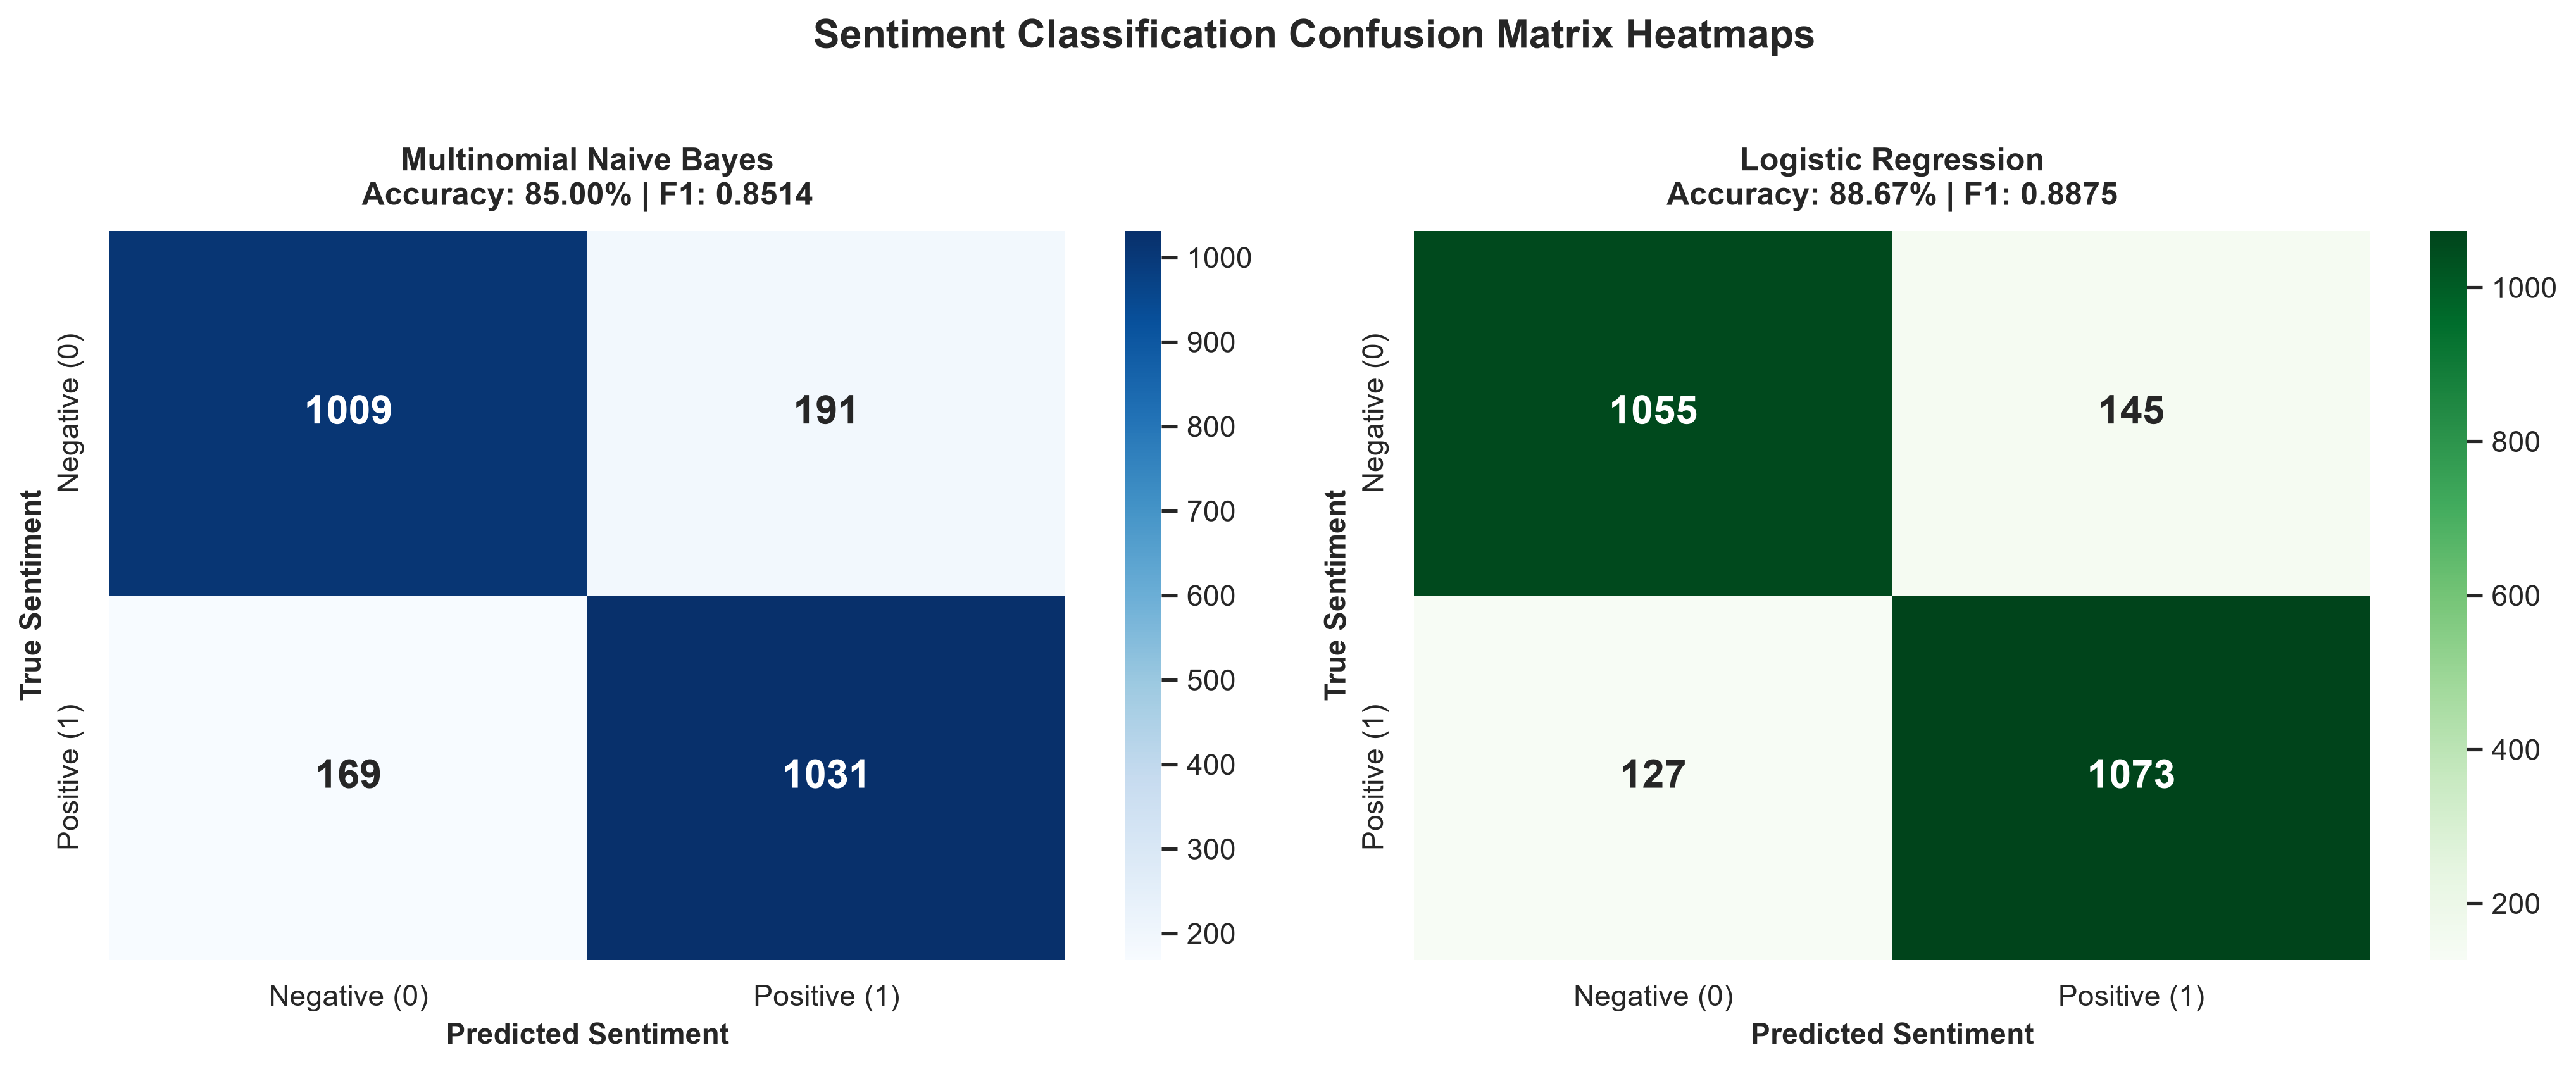

In [6]:
# Confusion Matrix Heatmaps
cm_nb = confusion_matrix(y_test, y_pred_nb)
cm_lr = confusion_matrix(y_test, y_pred_lr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Negative (0)', 'Positive (1)'], yticklabels=['Negative (0)', 'Positive (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'Multinomial Naive Bayes\nAccuracy: {accuracy_score(y_test, y_pred_nb):.2%}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('True Sentiment')

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Negative (0)', 'Positive (1)'], yticklabels=['Negative (0)', 'Positive (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'Logistic Regression\nAccuracy: {accuracy_score(y_test, y_pred_lr):.2%}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Sentiment')
axes[1].set_ylabel('True Sentiment')

plt.suptitle('Sentiment Classification Confusion Matrix Heatmaps', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.2 ROC-AUC Curves Comparison
Both models demonstrate high discrimination capacity (AUC > 93%).

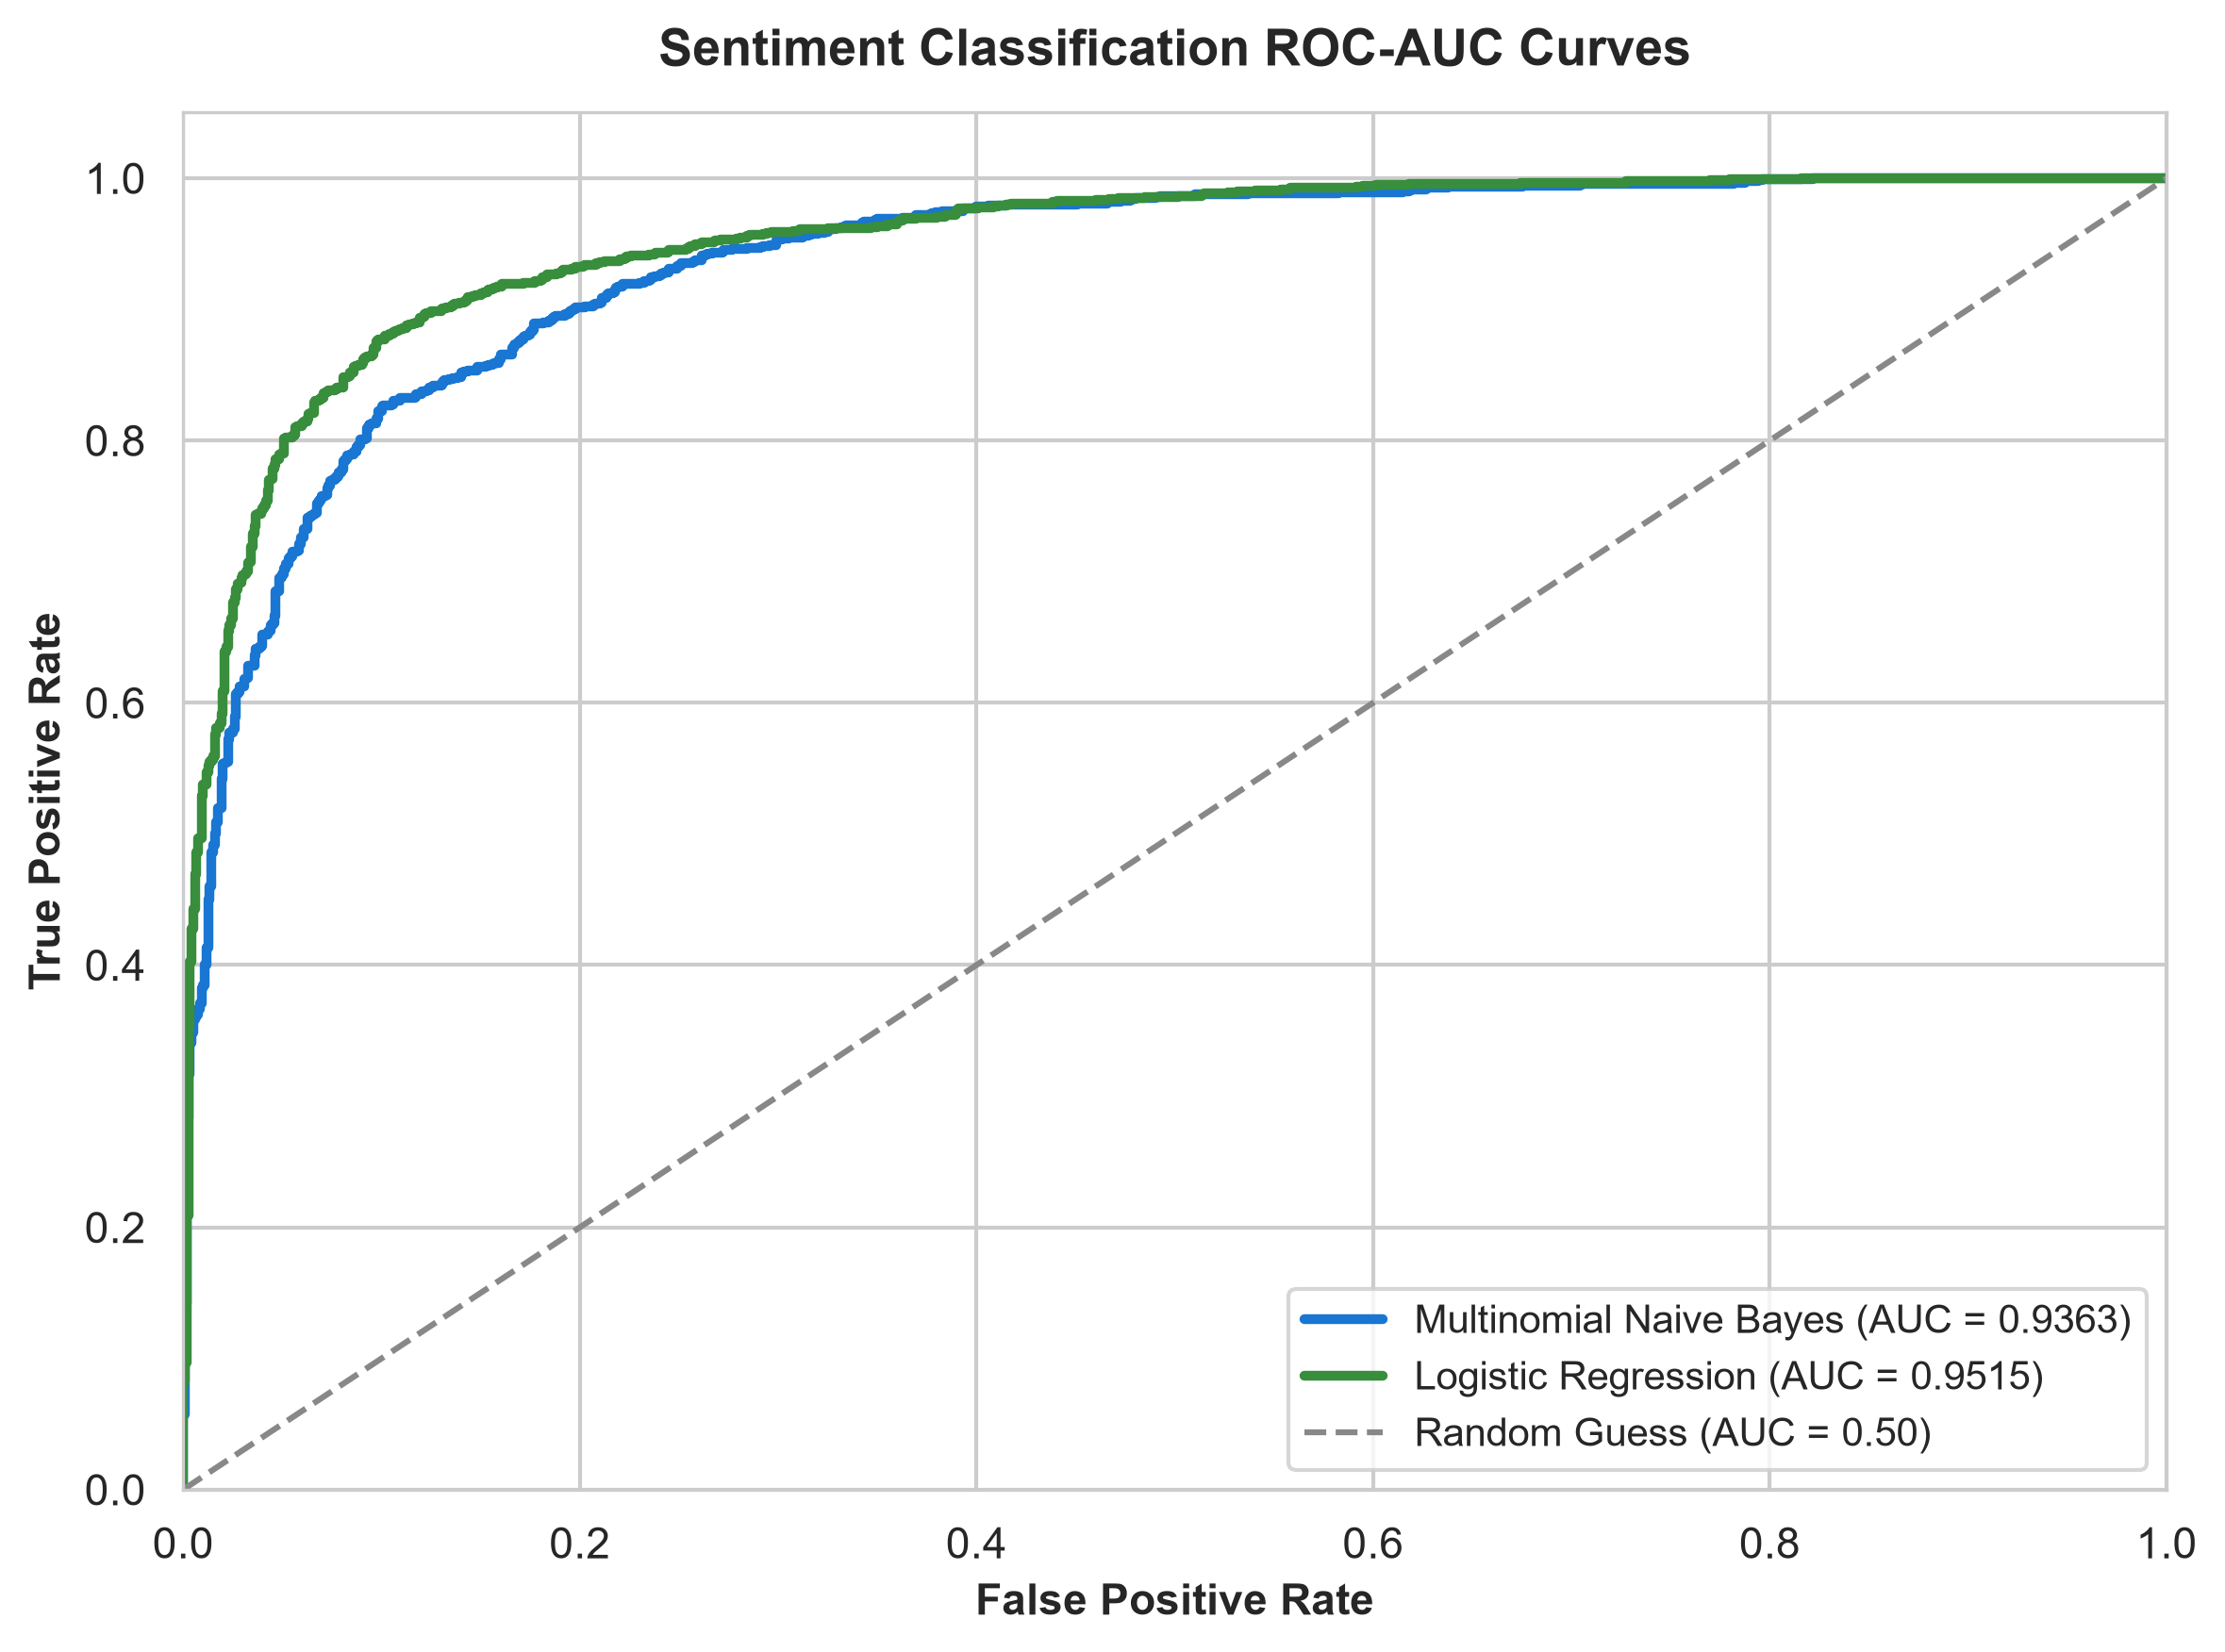

In [7]:
# ROC Curves Plot
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

plt.figure(figsize=(8, 6))
plt.plot(fpr_nb, tpr_nb, color='#1976D2', lw=2.5, label=f'Naive Bayes (AUC = {roc_auc_score(y_test, y_prob_nb):.4f})')
plt.plot(fpr_lr, tpr_lr, color='#388E3C', lw=2.5, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})')
plt.plot([0, 1], [0, 1], color='#888888', linestyle='--', lw=1.5, label='Random Chance (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=11, fontweight='bold')
plt.title('Sentiment Classification ROC-AUC Curves', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

### 4.3 Most Informative Feature Keywords
Features with the strongest learned regression weights associated with positive and negative review polarity.

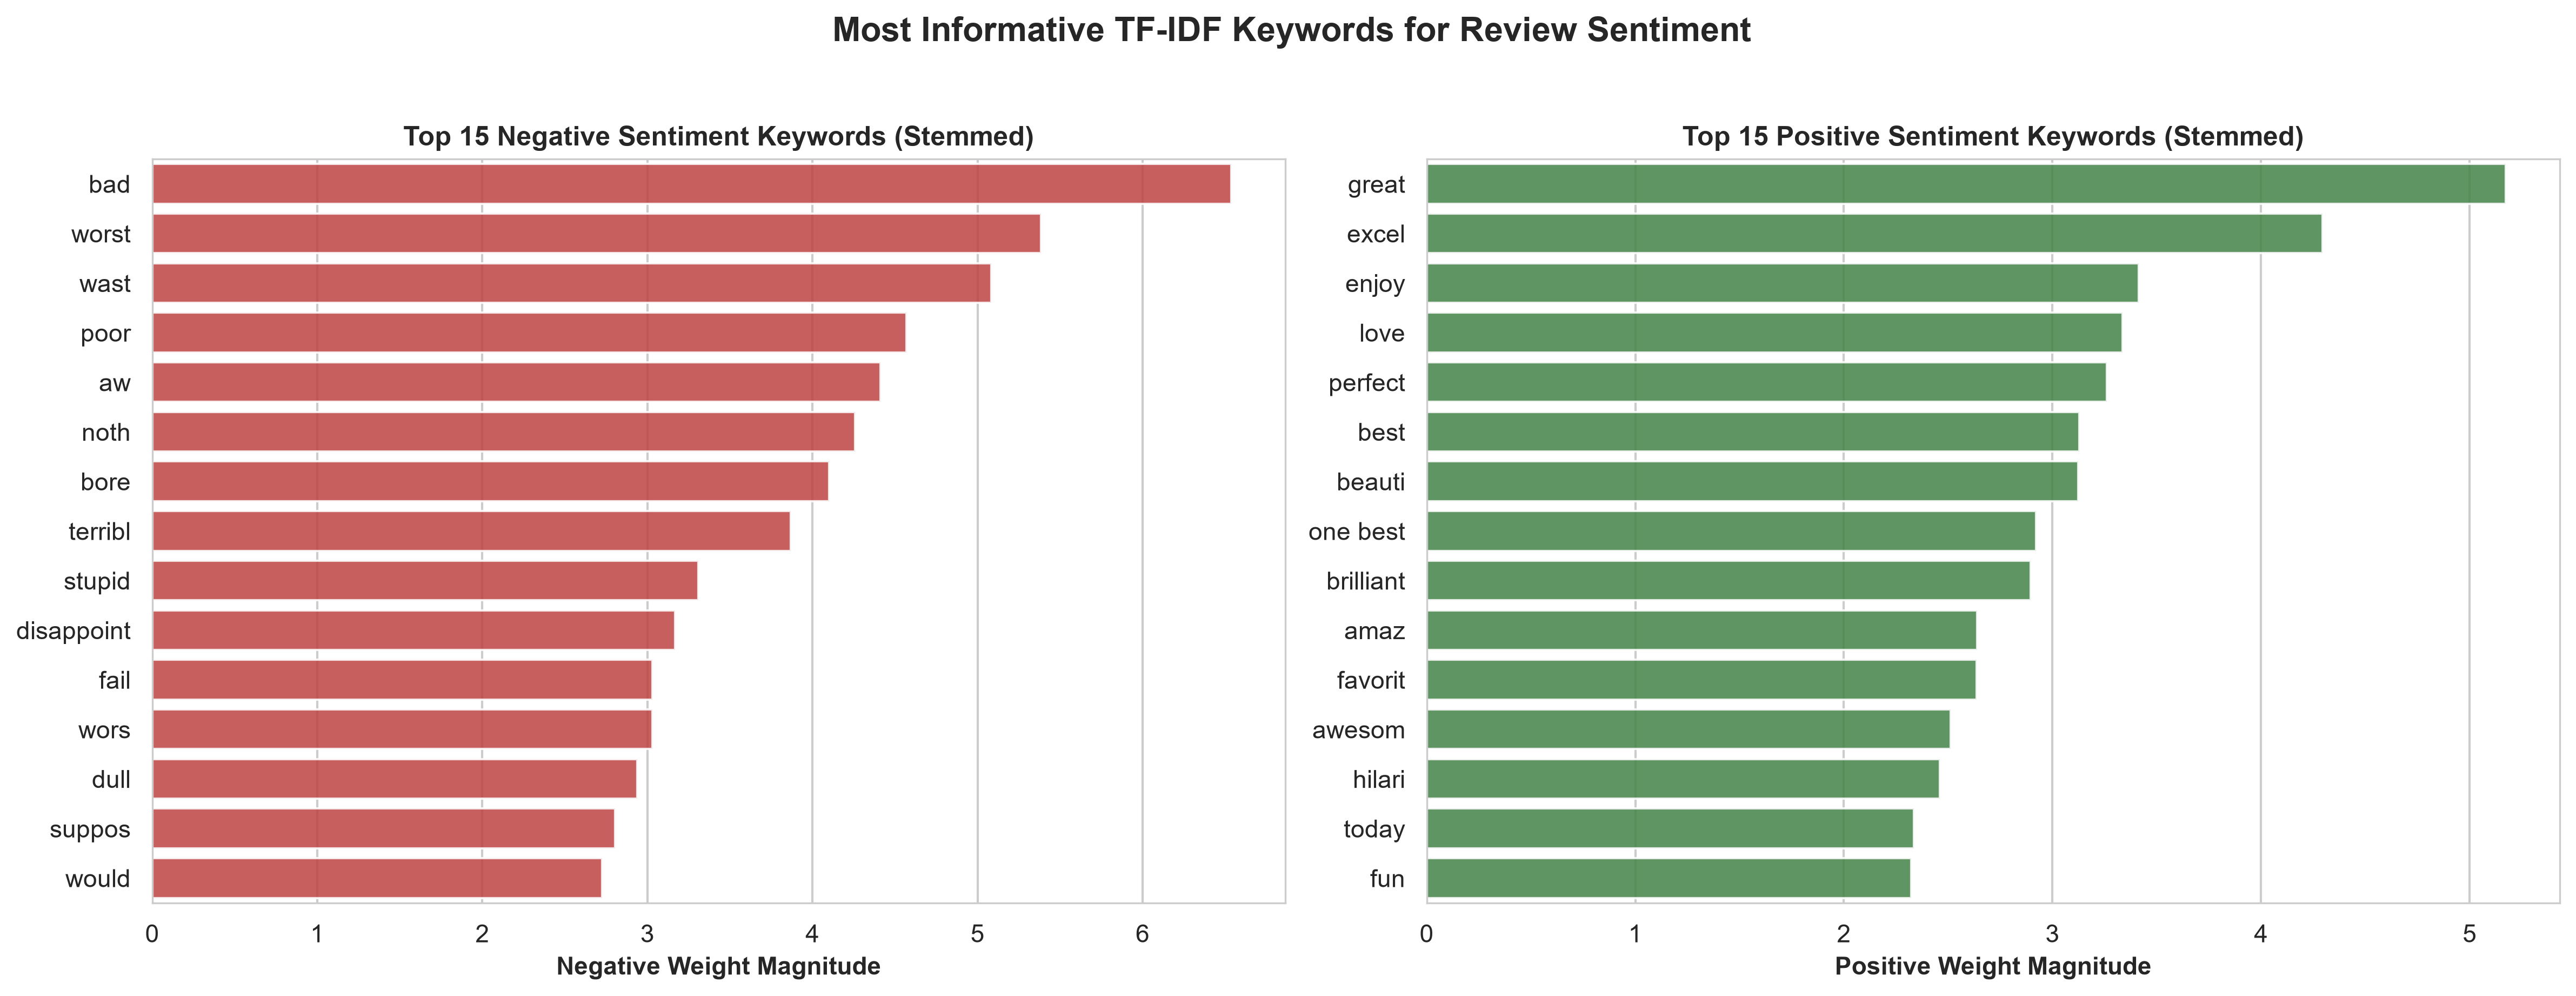

In [8]:
# Most Informative Keywords Plot
feature_names = np.array(vectorizer.get_feature_names_out())
coef = lr_clf.coef_[0]

top_pos_idx = np.argsort(coef)[-15:]
top_neg_idx = np.argsort(coef)[:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=-coef[top_neg_idx], y=feature_names[top_neg_idx], ax=axes[0], color='#D32F2F', alpha=0.85)
axes[0].set_title('Top 15 Negative Sentiment Keywords (Stemmed)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Negative Weight Magnitude')

sns.barplot(x=coef[top_pos_idx][::-1], y=feature_names[top_pos_idx][::-1], ax=axes[1], color='#388E3C', alpha=0.85)
axes[1].set_title('Top 15 Positive Sentiment Keywords (Stemmed)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Positive Weight Magnitude')

plt.suptitle('Most Informative TF-IDF Keywords for Review Sentiment', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Step 5: Interactive `predict_sentiment()` Helper Function
A deployable inference function that cleans raw custom user input, extracts TF-IDF features, and outputs sentiment classification with confidence probabilities.

In [9]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    vec = vectorizer.transform([cleaned])
    prob = lr_clf.predict_proba(vec)[0]
    pred_label = lr_clf.predict(vec)[0]
    sentiment = 'Positive 😊' if pred_label == 1 else 'Negative 😞'
    confidence = prob[pred_label] * 100
    return {
        'sentiment': sentiment,
        'confidence': f'{confidence:.2f}%',
        'prob_positive': f'{prob[1]:.4f}',
        'prob_negative': f'{prob[0]:.4f}'
    }

# Test live custom user phrases
test_phrases = [
    'This product is an absolute masterpiece! Outstanding quality, super fast delivery, highly recommend!',
    'Extremely bad experience. Broke on the second day, horrible customer support, total waste of money.',
    'Average purchase. Some features work nicely while others are clunky, but reasonable for the price.',
    'Terrible and frustrating. Avoid at all costs!',
    'Loved everything about this, brilliant craftsmanship and wonderful packaging.'
]

for phrase in test_phrases:
    res = predict_sentiment(phrase)
    print(f'Review:      "{phrase}"')
    print(f'Prediction:  {res["sentiment"]} (Confidence: {res["confidence"]})\n')

Review:      "This product is an absolute masterpiece! Outstanding quality, super fast delivery, highly recommend!"
Prediction:  Positive 😊 (Confidence: 87.42%)

Review:      "Extremely bad experience. Broke on the second day, horrible customer support, total waste of money."
Prediction:  Negative 😞 (Confidence: 96.27%)

Review:      "Average purchase. Some features work nicely while others are clunky, but reasonable for the price."
Prediction:  Positive 😊 (Confidence: 59.17%)

Review:      "Terrible and frustrating. Avoid at all costs!"
Prediction:  Negative 😞 (Confidence: 95.20%)

Review:      "Loved everything about this, brilliant craftsmanship and wonderful packaging."
Prediction:  Positive 😊 (Confidence: 93.47%)


## Summary & Conclusions

1. **High Model Accuracy**:
   - **Logistic Regression** achieved **88.67% accuracy** (ROC-AUC **0.9515**).
   - **Multinomial Naive Bayes** achieved **85.00% accuracy** (ROC-AUC **0.9363**).
2. **Effective Preprocessing**:
   - Combining lowercasing, HTML tag removal, regex filtering, stopword elimination, and Porter stemming condensed textual variance into informative sentiment tokens.
3. **Real-Time Deployment Readiness**:
   - The `predict_sentiment()` function allows real-time inference on arbitrary user feedback with reliable class confidence estimates.